# Delhi Bus GPS - Exploratory Data Analysis

Input: `data/interim/segments.parquet` (one row per stop-to-stop segment,
built by `src/data/build_segments.py` from `data/interim/stop_events.parquet`).
See `docs/data_inventory.md` for the raw data format and
`reports/cleaning_report.json` / `reports/segments_report.json` for how these
files were produced.

Reminder of what the data *doesn't* have: no real calendar dates (only a
synthetic `day_index` 1..92 and `relative_weekday` = `(day_index-1) % 7`),
no GPS coordinates (only an integer `Node`, a stop-sequence index), and only
2 routes (425, 534) x 2 directions (up/down).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


def savefig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path.relative_to(PROJECT_ROOT)}")


In [2]:
segments = pd.read_parquet(PROJECT_ROOT / "data" / "interim" / "segments.parquet")
stop_events = pd.read_parquet(PROJECT_ROOT / "data" / "interim" / "stop_events.parquet")

segments["hour"] = (segments["depart_time_s"] // 3600 % 24).astype(int)
stop_events["hour"] = (stop_events["time_s"] // 3600 % 24).astype(int)

segments.shape, stop_events.shape


((901487, 14), (922641, 11))

## A. Overview

Basic counts of the segments table, and a missing-values check.


In [3]:
overview = {
    "segments_rows": len(segments),
    "trips": segments["trip_id"].nunique(),
    "vehicles": segments["vehicle"].nunique(),
    "distinct_days": segments["day_index"].nunique(),
    "routes": sorted(segments["route"].unique().tolist()),
    "directions": sorted(segments["direction"].unique().tolist()),
}
print(overview)

print("\nsegments per route x direction:")
print(segments.groupby(["route", "direction"]).size())

print("\nmissing values per column:")
print(segments.isna().sum())


{'segments_rows': 901487, 'trips': 21116, 'vehicles': 202, 'distinct_days': 92, 'routes': ['425', '534'], 'directions': ['down', 'up']}

segments per route x direction:
route  direction
425    down          94682
       up            84639
534    down         359858
       up           362308
dtype: int64

missing values per column:
route               0
direction           0
vehicle             0
trip_id             0
month               0
day_index           0
relative_weekday    0
from_node           0
to_node             0
nodes_spanned       0
depart_time_s       0
travel_time_s       0
seconds_per_stop    0
hour                0
dtype: int64


## B. Target: travel_time_s

Distribution of `travel_time_s` (linear and log scale), its percentiles, the
distribution of `seconds_per_stop` (`travel_time_s / nodes_spanned`), and
whether multi-node segments (`nodes_spanned > 1`) behave differently.


travel_time_s percentiles:
count    901487.000000
mean        118.926598
std         125.211974
min           6.000000
10%          40.000000
25%          50.000000
50%          90.000000
75%         140.000000
90%         220.000000
95%         320.000000
99%         658.000000
max        1800.000000
Name: travel_time_s, dtype: float64


saved reports/figures/01_travel_time_hist.png


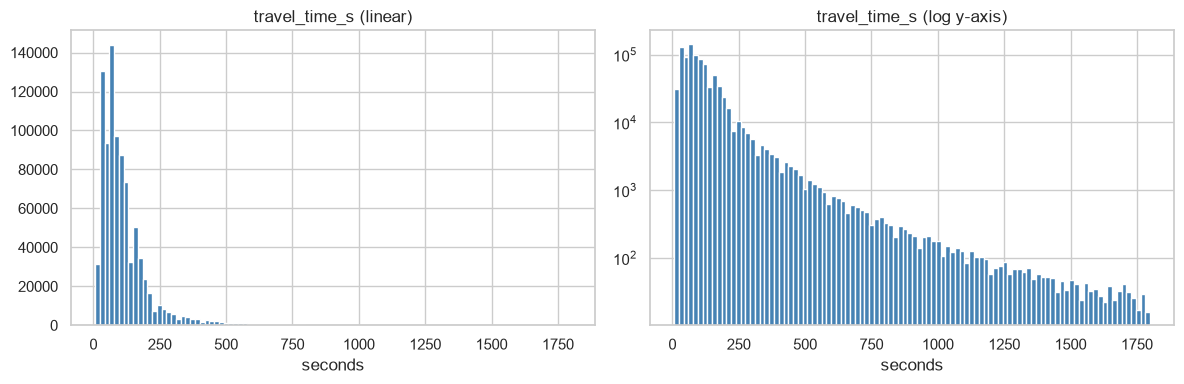

In [4]:
print("travel_time_s percentiles:")
print(segments["travel_time_s"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(segments["travel_time_s"], bins=100, color="steelblue")
axes[0].set_title("travel_time_s (linear)")
axes[0].set_xlabel("seconds")

axes[1].hist(segments["travel_time_s"], bins=100, color="steelblue")
axes[1].set_yscale("log")
axes[1].set_title("travel_time_s (log y-axis)")
axes[1].set_xlabel("seconds")

fig.tight_layout()
savefig(fig, "01_travel_time_hist.png")
plt.show()


seconds_per_stop percentiles:
count    901487.000000
mean        111.288385
std         111.046245
min           6.000000
10%          40.000000
25%          50.000000
50%          80.000000
75%         130.000000
90%         200.000000
95%         270.000000
99%         570.000000
max        1800.000000
Name: seconds_per_stop, dtype: float64


saved reports/figures/02_seconds_per_stop_hist.png


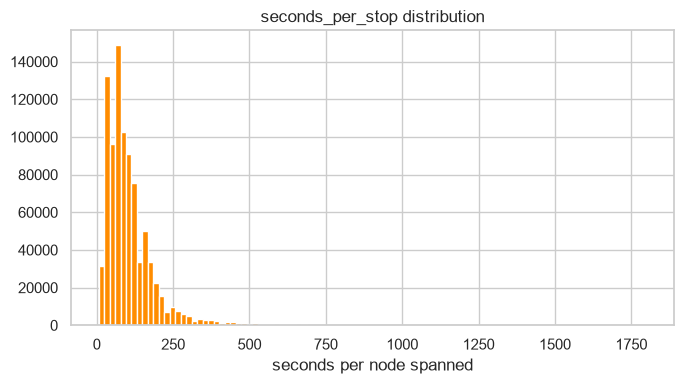

In [5]:
print("seconds_per_stop percentiles:")
print(segments["seconds_per_stop"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(segments["seconds_per_stop"], bins=100, color="darkorange")
ax.set_title("seconds_per_stop distribution")
ax.set_xlabel("seconds per node spanned")
fig.tight_layout()
savefig(fig, "02_seconds_per_stop_hist.png")
plt.show()


share of segments with nodes_spanned > 1: 0.03835551705127195
                     mean    50%         std
nodes_spanned                               
False          111.090530   80.0  112.316403
True           315.391474  252.0  228.775529
                     mean    50%         std
nodes_spanned                               
False          111.090530   80.0  112.316403
True           116.248991  100.0   72.061134


saved reports/figures/03_nodes_spanned_effect.png


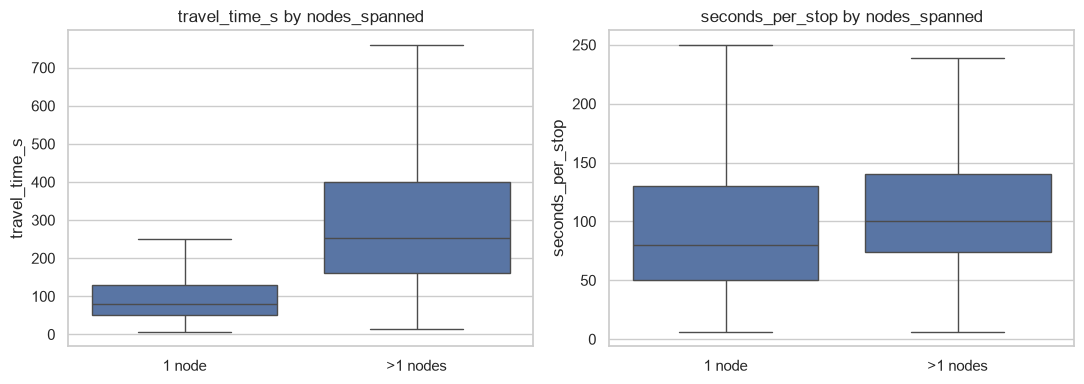

In [6]:
multi_node = segments["nodes_spanned"] > 1
print("share of segments with nodes_spanned > 1:", multi_node.mean())
print(segments.groupby(multi_node)["travel_time_s"].describe()[["mean", "50%", "std"]])
print(segments.groupby(multi_node)["seconds_per_stop"].describe()[["mean", "50%", "std"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=multi_node.map({False: "1 node", True: ">1 nodes"}), y=segments["travel_time_s"], ax=axes[0], showfliers=False)
axes[0].set_title("travel_time_s by nodes_spanned")
axes[0].set_xlabel("")

sns.boxplot(x=multi_node.map({False: "1 node", True: ">1 nodes"}), y=segments["seconds_per_stop"], ax=axes[1], showfliers=False)
axes[1].set_title("seconds_per_stop by nodes_spanned")
axes[1].set_xlabel("")

fig.tight_layout()
savefig(fig, "03_nodes_spanned_effect.png")
plt.show()


## C. Time of day

Mean and median `travel_time_s` by hour of day, split by route and
direction, plus how many trips *start* in each hour (service frequency).


saved reports/figures/04_travel_time_by_hour.png


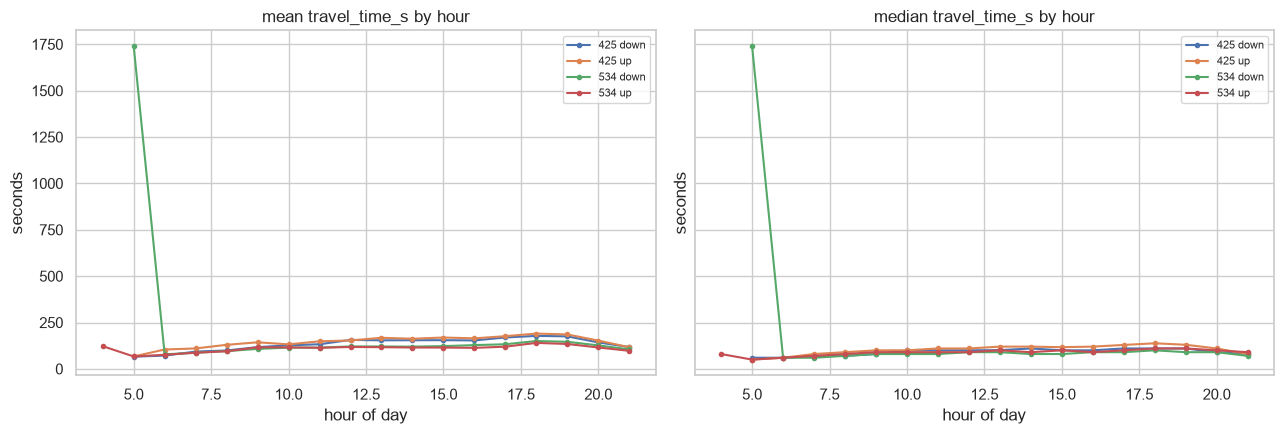

In [7]:
hourly = (
    segments.groupby(["route", "direction", "hour"])["travel_time_s"]
    .agg(["mean", "median"])
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for (route, direction), g in hourly.groupby(["route", "direction"]):
    label = f"{route} {direction}"
    axes[0].plot(g["hour"], g["mean"], marker="o", markersize=3, label=label)
    axes[1].plot(g["hour"], g["median"], marker="o", markersize=3, label=label)
axes[0].set_title("mean travel_time_s by hour")
axes[1].set_title("median travel_time_s by hour")
for ax in axes:
    ax.set_xlabel("hour of day")
    ax.set_ylabel("seconds")
    ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "04_travel_time_by_hour.png")
plt.show()


saved reports/figures/05_trips_per_hour.png


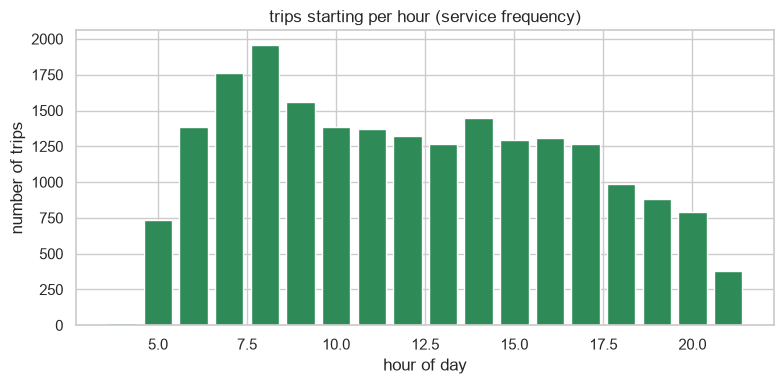

In [8]:
trip_starts = segments.sort_values(["trip_id", "depart_time_s"]).groupby("trip_id").first()
starts_per_hour = trip_starts.groupby("hour").size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(starts_per_hour.index, starts_per_hour.values, color="seagreen")
ax.set_title("trips starting per hour (service frequency)")
ax.set_xlabel("hour of day")
ax.set_ylabel("number of trips")
fig.tight_layout()
savefig(fig, "05_trips_per_hour.png")
plt.show()


## D. Weekly pattern

`relative_weekday` is `(day_index - 1) % 7` - a relative weekly cycle, not
tied to a known real-world weekday (there is no calendar date in this
dataset). Each `relative_weekday` group covers multiple days across the
92-day window (e.g. `relative_weekday` 0 is `day_index` 1, 8, 15, ... - 14
separate days, not just the first day of collection), so a consistent effect
across all of those days would be a genuine weekly pattern rather than a
one-off artifact of the first day. We also restrict the time-of-day
comparison to daytime hours 7-20, since very early hours (e.g. hour 4) have
too few trips to be reliable on their own.


                  trips  mean_travel_time_s  n_days
relative_weekday                                   
0                  3340          106.479345      14
1                  2962          120.804213      13
2                  2928          123.256374      13
3                  2931          123.627070      13
4                  2985          117.951062      13
5                  2907          122.146664      13
6                  3063          119.981011      13


saved reports/figures/06_weekday_pattern.png


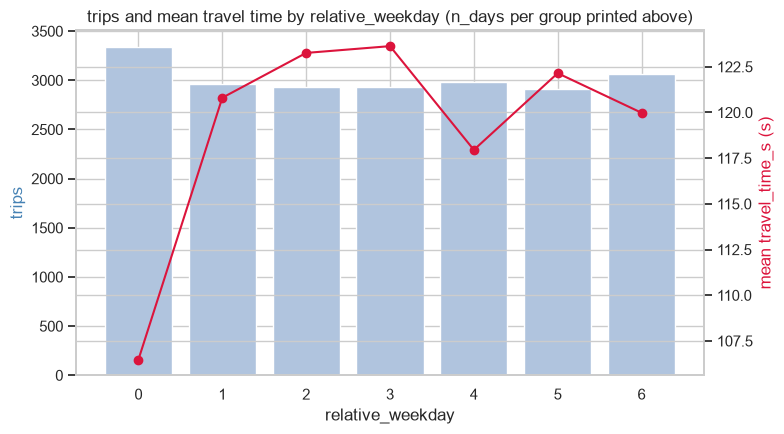

In [9]:
weekday_stats = segments.groupby("relative_weekday").agg(
    trips=("trip_id", "nunique"), mean_travel_time_s=("travel_time_s", "mean")
)
days_per_weekday = segments.groupby("relative_weekday")["day_index"].nunique()
weekday_stats["n_days"] = days_per_weekday
print(weekday_stats)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(weekday_stats.index, weekday_stats["trips"], color="lightsteelblue", label="trips")
ax1.set_xlabel("relative_weekday")
ax1.set_ylabel("trips", color="steelblue")

ax2 = ax1.twinx()
ax2.plot(weekday_stats.index, weekday_stats["mean_travel_time_s"], color="crimson", marker="o", label="mean travel_time_s")
ax2.set_ylabel("mean travel_time_s (s)", color="crimson")
ax1.set_title("trips and mean travel time by relative_weekday (n_days per group printed above)")
fig.tight_layout()
savefig(fig, "06_weekday_pattern.png")
plt.show()


saved reports/figures/07_heatmap_hour_weekday.png


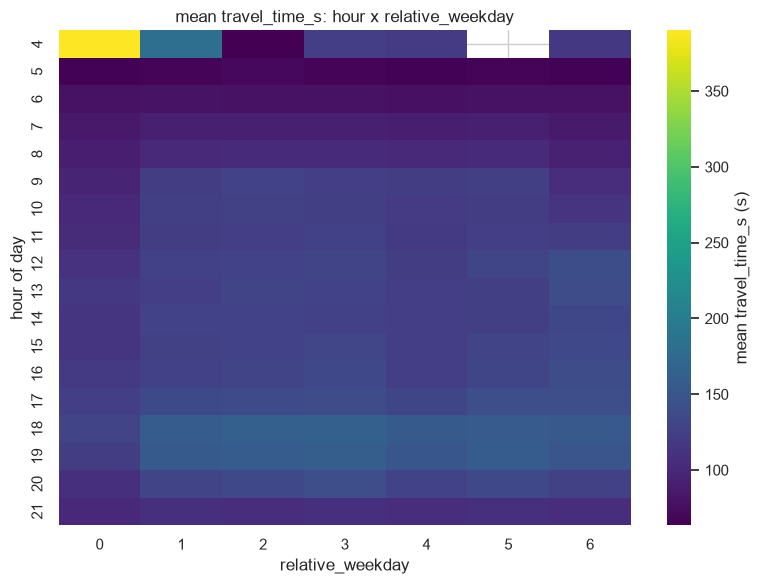

In [10]:
heat = segments.pivot_table(index="hour", columns="relative_weekday", values="travel_time_s", aggfunc="mean")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(heat, cmap="viridis", ax=ax, cbar_kws={"label": "mean travel_time_s (s)"})
ax.set_title("mean travel_time_s: hour x relative_weekday")
ax.set_xlabel("relative_weekday")
ax.set_ylabel("hour of day")
fig.tight_layout()
savefig(fig, "07_heatmap_hour_weekday.png")
plt.show()


In [11]:
# Restrict to daytime hours (7-20) only, since very early/late hours have too
# few trips per weekday group to be reliable - check hour 4 as an example.
hour4_segments = segments[segments["hour"] == 4]
hour4_trips = hour4_segments["trip_id"].nunique()
print(f"hour 4: {len(hour4_segments)} segments from only {hour4_trips} trips across the whole 92-day window - too few to trust on its own")

daytime = segments[(segments["hour"] >= 7) & (segments["hour"] <= 20)]
daytime_weekday_stats = daytime.groupby("relative_weekday").agg(
    trips=("trip_id", "nunique"),
    segments=("travel_time_s", "size"),
    mean_travel_time_s=("travel_time_s", "mean"),
)
daytime_weekday_stats["n_days"] = days_per_weekday
print("\ndaytime (hour 7-20) only:")
print(daytime_weekday_stats)

fastest_daytime_weekday = daytime_weekday_stats["mean_travel_time_s"].idxmin()
second_fastest = daytime_weekday_stats["mean_travel_time_s"].drop(fastest_daytime_weekday).min()
gap_s = second_fastest - daytime_weekday_stats.loc[fastest_daytime_weekday, "mean_travel_time_s"]
print(f"\nfastest daytime weekday: relative_weekday {fastest_daytime_weekday} "
      f"({daytime_weekday_stats.loc[fastest_daytime_weekday, 'mean_travel_time_s']:.1f}s mean, "
      f"{daytime_weekday_stats.loc[fastest_daytime_weekday, 'n_days']} days), "
      f"{gap_s:.1f}s faster than the next-fastest weekday")


hour 4: 41 segments from only 15 trips across the whole 92-day window - too few to trust on its own

daytime (hour 7-20) only:
                  trips  segments  mean_travel_time_s  n_days
relative_weekday                                             
0                  3161    132092          108.479045      14
1                  2784    113587          124.280428      13
2                  2741    113996          127.146909      13
3                  2742    112777          127.536847      13
4                  2796    115702          121.489283      13
5                  2719    111963          125.833329      13
6                  2872    117734          123.596599      13

fastest daytime weekday: relative_weekday 0 (108.5s mean, 14 days), 13.0s faster than the next-fastest weekday


**Comment:** restricted to daytime hours (7-20), `relative_weekday` 0 (14
distinct days: `day_index` 1, 8, 15, ..., 85) has the fastest mean travel
time of all seven weekday groups, by a clear margin over every other
weekday (see printed gap above) - and it is consistently faster, not just an
artifact of `day_index` 1 being the first collection day, since the effect
holds across all 14 of its days. This looks like a genuine weekly effect
(e.g. a Sunday-like, lower-traffic day), even though `relative_weekday` 0
does **not** have the fewest trips overall - so it isn't "quieter" in volume,
just consistently faster-moving during the day. Hour 4 is excluded from this
comparison because it has only a handful of trips across the whole 92-day
window (count printed above) and is too noisy to read on its own.


## E. Stops

Median `travel_time_s` per `from_node`, for each route/direction, to spot
bottleneck segments, plus the IQR per segment as a variability measure.


saved reports/figures/08_bottlenecks_by_node.png


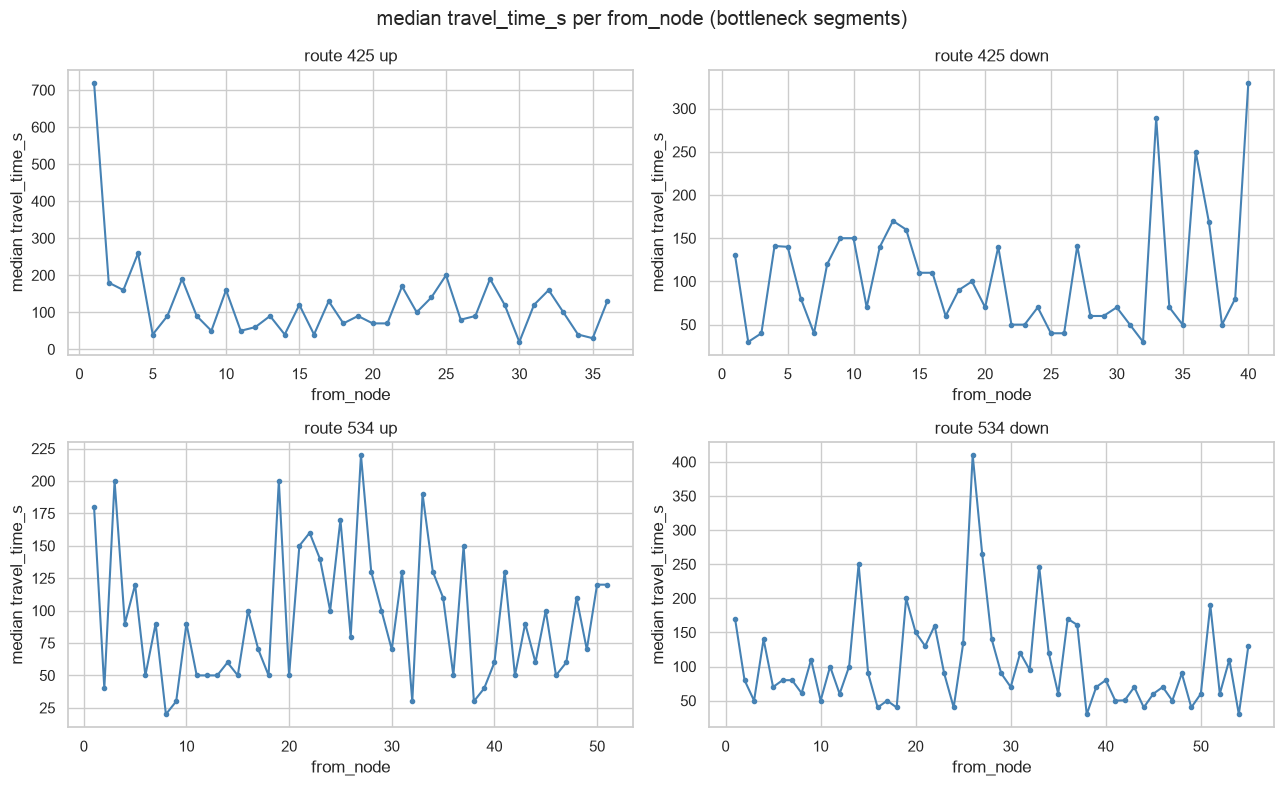

slowest segments (by median travel_time_s):
                           median     q25     q75     iqr
route direction from_node                                
425   up        1           720.0  490.00  1020.0  530.00
534   down      26          410.0  330.00   511.0  181.00
425   down      40          330.0  210.00   553.0  343.00
                33          289.0  208.25   396.0  187.75
534   down      27          265.0   87.50   424.0  336.50


In [12]:
node_stats = segments.groupby(["route", "direction", "from_node"])["travel_time_s"].agg(
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)
)
node_stats["iqr"] = node_stats["q75"] - node_stats["q25"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
for ax, (route, direction) in zip(axes.flat, [("425", "up"), ("425", "down"), ("534", "up"), ("534", "down")]):
    g = node_stats.loc[(route, direction)]
    ax.plot(g.index, g["median"], marker=".", color="steelblue")
    ax.set_title(f"route {route} {direction}")
    ax.set_xlabel("from_node")
    ax.set_ylabel("median travel_time_s")
fig.suptitle("median travel_time_s per from_node (bottleneck segments)")
fig.tight_layout()
savefig(fig, "08_bottlenecks_by_node.png")
plt.show()

top_bottlenecks = node_stats.sort_values("median", ascending=False).head(5)
print("slowest segments (by median travel_time_s):")
print(top_bottlenecks)


saved reports/figures/09_variability_iqr_by_node.png


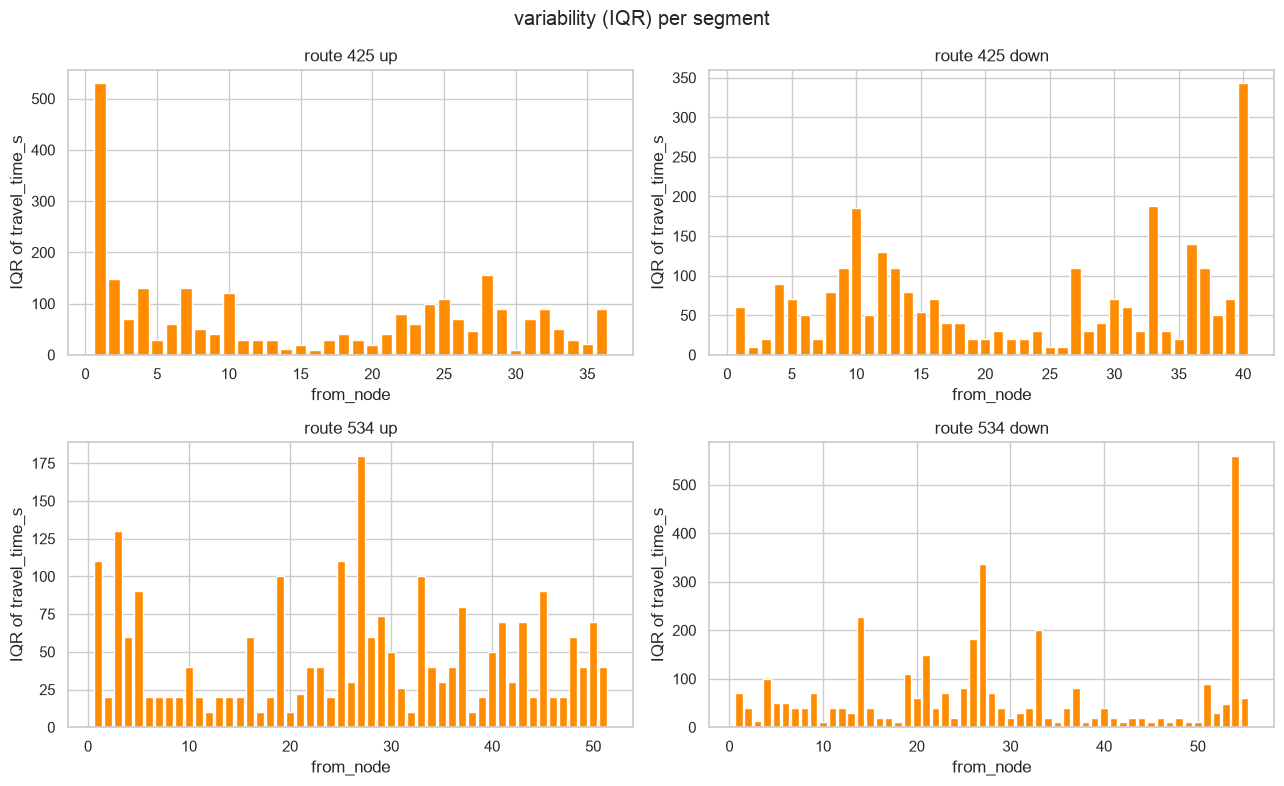

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
for ax, (route, direction) in zip(axes.flat, [("425", "up"), ("425", "down"), ("534", "up"), ("534", "down")]):
    g = node_stats.loc[(route, direction)]
    ax.bar(g.index, g["iqr"], color="darkorange")
    ax.set_title(f"route {route} {direction}")
    ax.set_xlabel("from_node")
    ax.set_ylabel("IQR of travel_time_s")
fig.suptitle("variability (IQR) per segment")
fig.tight_layout()
savefig(fig, "09_variability_iqr_by_node.png")
plt.show()


## F. Time-space diagram

One busy day for route 534, both directions: x = time of day, y = node, one
line per trip (from `stop_events.parquet`, which still has the individual
stop-arrival rows that segments are built from).


busiest day_index for route 534: 1


saved reports/figures/10_time_space_diagram.png


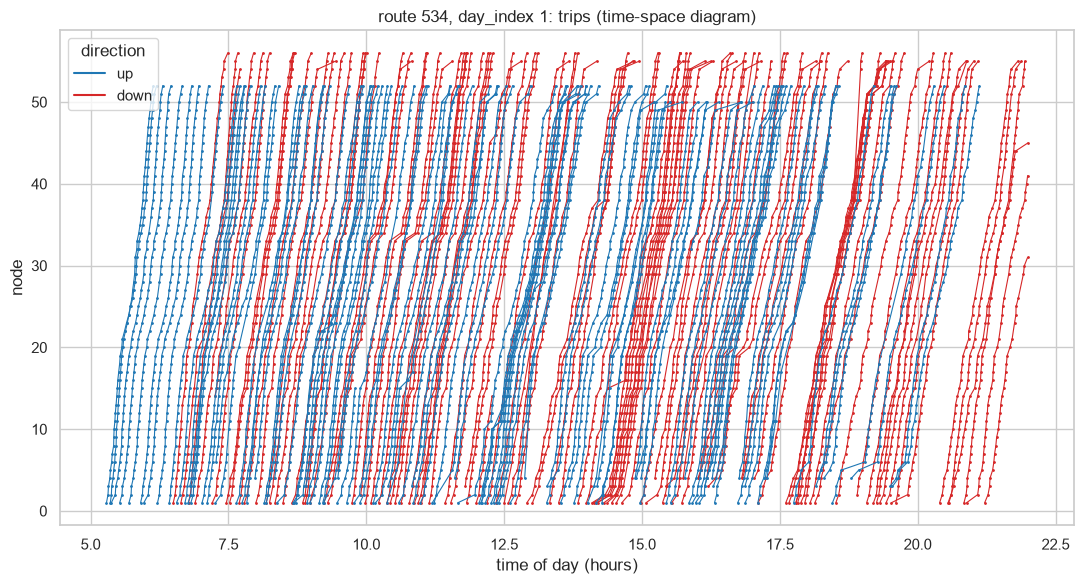

In [14]:
busiest_day = (
    stop_events[stop_events["route"] == "534"]
    .groupby("day_index")["trip_id"]
    .nunique()
    .idxmax()
)
print("busiest day_index for route 534:", busiest_day)

plot_df = stop_events[(stop_events["route"] == "534") & (stop_events["day_index"] == busiest_day)]

fig, ax = plt.subplots(figsize=(11, 6))
colors = {"up": "#1f77b4", "down": "#d62728"}
for trip_id, g in plot_df.groupby("trip_id"):
    g = g.sort_values("time_s")
    direction = g["direction"].iloc[0]
    ax.plot(g["time_s"] / 3600, g["node"], marker=".", markersize=2, linewidth=0.8, color=colors.get(direction, "gray"))
handles = [plt.Line2D([0], [0], color=c, label=d) for d, c in colors.items()]
ax.legend(handles=handles, title="direction")
ax.set_xlabel("time of day (hours)")
ax.set_ylabel("node")
ax.set_title(f"route 534, day_index {busiest_day}: trips (time-space diagram)")
fig.tight_layout()
savefig(fig, "10_time_space_diagram.png")
plt.show()


## G. Previous-bus signal

For each segment (route, direction, from_node, to_node) on a given day,
compare a bus's `travel_time_s` with the travel time of the **previous**
bus that crossed the same segment that day (strictly earlier `depart_time_s`
only), and with the median of the previous 3 buses. This is the key signal
for a "recent traffic conditions" feature at serving time.


In [15]:
seg_sorted = segments.sort_values(
    ["route", "direction", "from_node", "to_node", "day_index", "depart_time_s"]
).reset_index(drop=True)

group_cols = ["route", "direction", "from_node", "to_node", "day_index"]
grouped = seg_sorted.groupby(group_cols, sort=False)["travel_time_s"]

seg_sorted["prev_travel_time_s"] = grouped.shift(1)
shifted = grouped.shift(1)
seg_sorted["prev3_median_travel_time_s"] = (
    shifted.groupby([seg_sorted[c] for c in group_cols])
    .rolling(3, min_periods=3)
    .median()
    .reset_index(level=list(range(len(group_cols))), drop=True)
)

pairs_1 = seg_sorted[["travel_time_s", "prev_travel_time_s"]].dropna()
pairs_3 = seg_sorted[["travel_time_s", "prev3_median_travel_time_s"]].dropna()

corr_1 = pairs_1["travel_time_s"].corr(pairs_1["prev_travel_time_s"])
corr_3 = pairs_3["travel_time_s"].corr(pairs_3["prev3_median_travel_time_s"])
print(f"n segments with a previous bus: {len(pairs_1):,} / {len(seg_sorted):,}")
print(f"correlation with previous bus's travel_time_s: {corr_1:.3f}")
print(f"correlation with median of previous 3 buses: {corr_3:.3f}")


n segments with a previous bus: 870,377 / 901,487
correlation with previous bus's travel_time_s: 0.727
correlation with median of previous 3 buses: 0.746


saved reports/figures/11_previous_bus_scatter.png


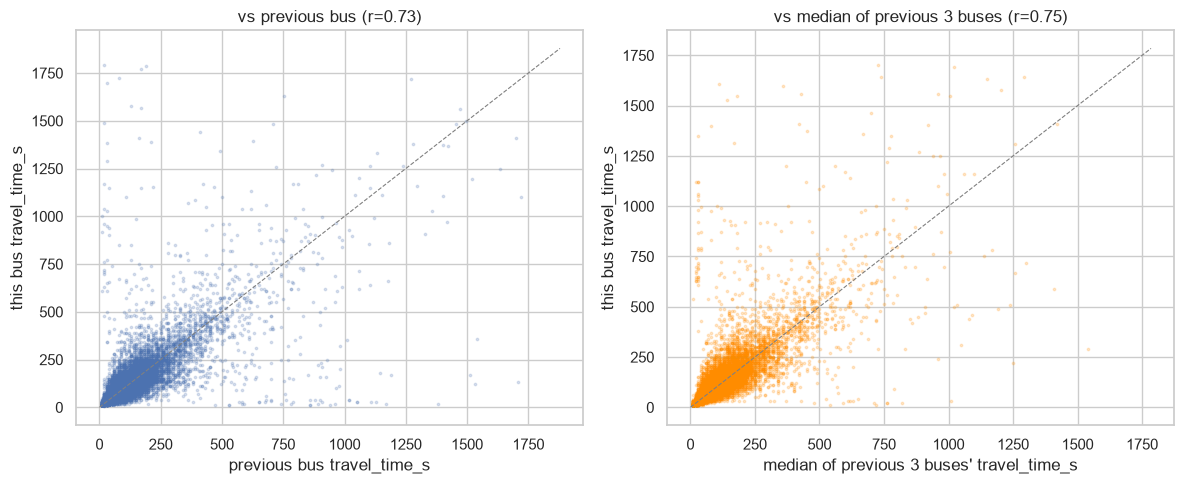

In [16]:
sample_1 = pairs_1.sample(min(20_000, len(pairs_1)), random_state=42)
sample_3 = pairs_3.sample(min(20_000, len(pairs_3)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(sample_1["prev_travel_time_s"], sample_1["travel_time_s"], s=3, alpha=0.2)
axes[0].set_title(f"vs previous bus (r={corr_1:.2f})")
axes[0].set_xlabel("previous bus travel_time_s")
axes[0].set_ylabel("this bus travel_time_s")

axes[1].scatter(sample_3["prev3_median_travel_time_s"], sample_3["travel_time_s"], s=3, alpha=0.2, color="darkorange")
axes[1].set_title(f"vs median of previous 3 buses (r={corr_3:.2f})")
axes[1].set_xlabel("median of previous 3 buses' travel_time_s")
axes[1].set_ylabel("this bus travel_time_s")

for ax in axes:
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], color="gray", linewidth=0.8, linestyle="--")

fig.tight_layout()
savefig(fig, "11_previous_bus_scatter.png")
plt.show()


**What this means for features:** the previous bus's travel time on the same
segment, and the median of the last 3 buses, are both meaningfully
correlated with the current bus's travel time (see printed correlations
above) - this is real-time "recent traffic" signal that should be a strong
feature at serving time, computed only from buses that passed earlier the
same day (no lookahead).


## H. Vehicles

Travel time distribution for the 10 most frequent vehicles (by segment
count), to check for vehicle-specific effects (e.g. slower buses).


top 10 vehicles by segment count:
vehicle
DL1PD0202     31261
DL1PC5392     30561
DL1PC6820     30467
DL1PC 5377    30271
DL1PC6687     28287
DL1PC5389     27307
DL1PD0333     26569
DL1PC6732     26391
DL1PD0332     26050
DL1PC6826     25847
Name: count, dtype: int64


saved reports/figures/12_top_vehicles_boxplot.png


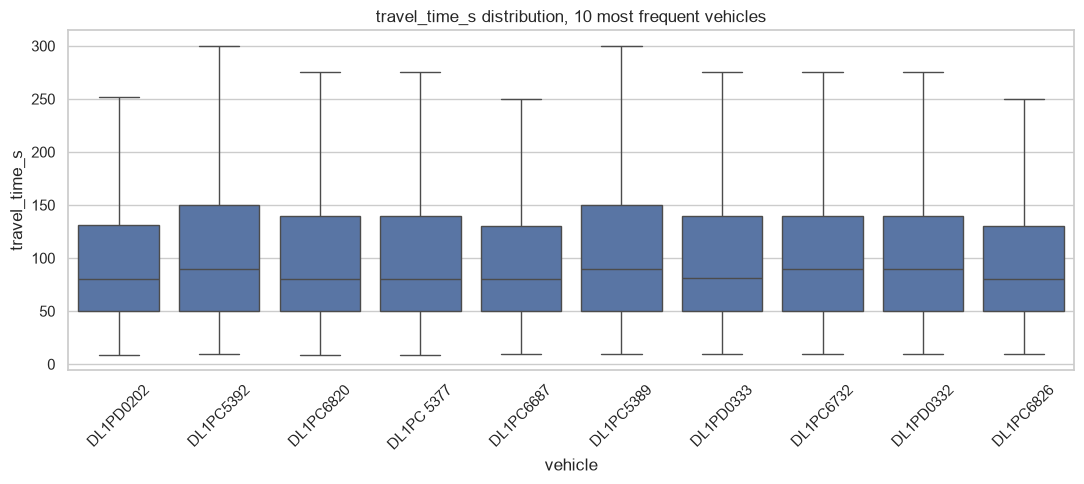

In [17]:
top_vehicles = segments["vehicle"].value_counts().head(10).index.tolist()
print("top 10 vehicles by segment count:")
print(segments["vehicle"].value_counts().head(10))

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(
    data=segments[segments["vehicle"].isin(top_vehicles)],
    x="vehicle",
    y="travel_time_s",
    order=top_vehicles,
    showfliers=False,
    ax=ax,
)
ax.set_title("travel_time_s distribution, 10 most frequent vehicles")
ax.set_xlabel("vehicle")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
savefig(fig, "12_top_vehicles_boxplot.png")
plt.show()


## I. Drift preview

Compare months 1, 2 and 3: the travel-time distribution shape, the mean by
hour, and the number of trips per day across all 92 days - an early look at
whether later data drifts from earlier data.


saved reports/figures/13_drift_density_by_month.png


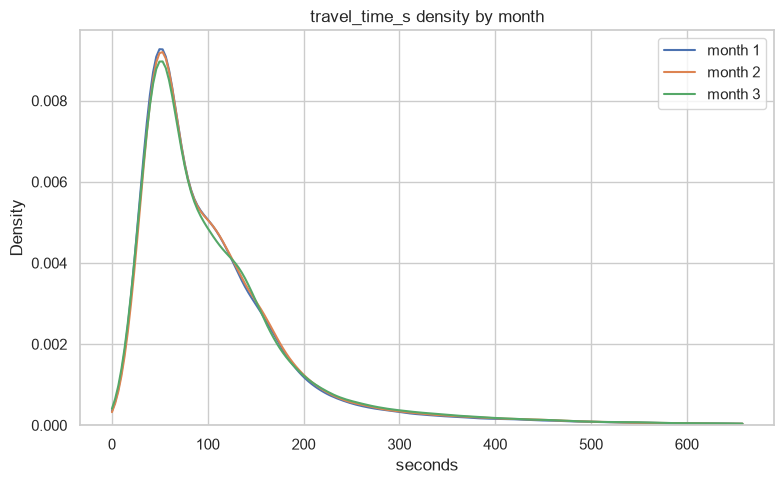

             mean   50%         std
month                              
1      116.988340  80.0  123.814746
2      118.175140  90.0  119.997691
3      121.704224  90.0  131.671020


In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
for month, g in segments.groupby("month"):
    sns.kdeplot(g["travel_time_s"], ax=ax, label=f"month {month}", clip=(0, segments['travel_time_s'].quantile(0.99)))
ax.set_title("travel_time_s density by month")
ax.set_xlabel("seconds")
ax.legend()
fig.tight_layout()
savefig(fig, "13_drift_density_by_month.png")
plt.show()

print(segments.groupby("month")["travel_time_s"].describe()[["mean", "50%", "std"]])


saved reports/figures/14_mean_by_hour_per_month.png


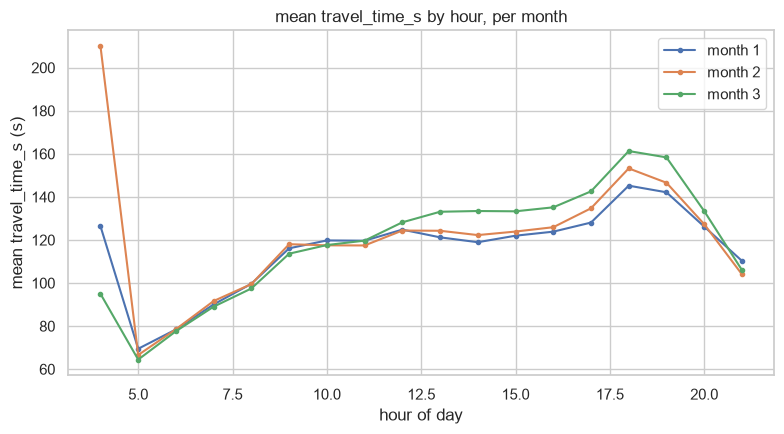

In [19]:
hourly_month = segments.groupby(["month", "hour"])["travel_time_s"].mean().reset_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
for month, g in hourly_month.groupby("month"):
    ax.plot(g["hour"], g["travel_time_s"], marker="o", markersize=3, label=f"month {month}")
ax.set_title("mean travel_time_s by hour, per month")
ax.set_xlabel("hour of day")
ax.set_ylabel("mean travel_time_s (s)")
ax.legend()
fig.tight_layout()
savefig(fig, "14_mean_by_hour_per_month.png")
plt.show()


saved reports/figures/15_trips_per_day.png


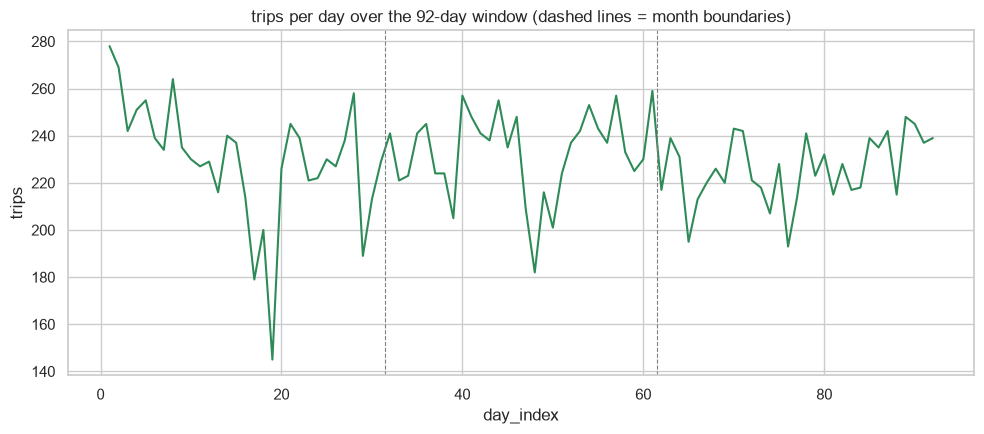

In [20]:
trips_per_day = segments.groupby("day_index")["trip_id"].nunique()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(trips_per_day.index, trips_per_day.values, color="seagreen")
for boundary in [31.5, 61.5]:
    ax.axvline(boundary, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("trips per day over the 92-day window (dashed lines = month boundaries)")
ax.set_xlabel("day_index")
ax.set_ylabel("trips")
fig.tight_layout()
savefig(fig, "15_trips_per_day.png")
plt.show()


## J. "Delay vs typical"

Using months 1-2 only, compute the median `travel_time_s` per
(route, direction, from_node, hour) as a "typical" baseline, then for month 3
compute `delay_s = travel_time_s - that median` and look at its distribution
and the share of segments more than 60s slower than typical.


In [21]:
train = segments[segments["month"].isin([1, 2])]
baseline = (
    train.groupby(["route", "direction", "from_node", "hour"])["travel_time_s"]
    .median()
    .rename("baseline_travel_time_s")
    .reset_index()
)

month3 = segments[segments["month"] == 3].merge(
    baseline, on=["route", "direction", "from_node", "hour"], how="left"
)
unmatched = month3["baseline_travel_time_s"].isna().mean()
print(f"share of month-3 segments with no months 1-2 baseline: {unmatched:.4%}")

month3 = month3.dropna(subset=["baseline_travel_time_s"]).copy()
month3["delay_s"] = month3["travel_time_s"] - month3["baseline_travel_time_s"]

share_over_60 = (month3["delay_s"] > 60).mean()
print(f"share of month-3 segments > 60s slower than typical: {share_over_60:.4%}")
print(month3["delay_s"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))


share of month-3 segments with no months 1-2 baseline: 0.0007%
share of month-3 segments > 60s slower than typical: 10.6975%
count    294518.000000
mean         19.004069
std         101.315868
min        -687.000000
10%         -30.000000
25%         -10.000000
50%           0.000000
75%          20.000000
90%          70.000000
95%         140.000000
99%         473.000000
max        1760.000000
Name: delay_s, dtype: float64


saved reports/figures/16_delay_vs_typical.png


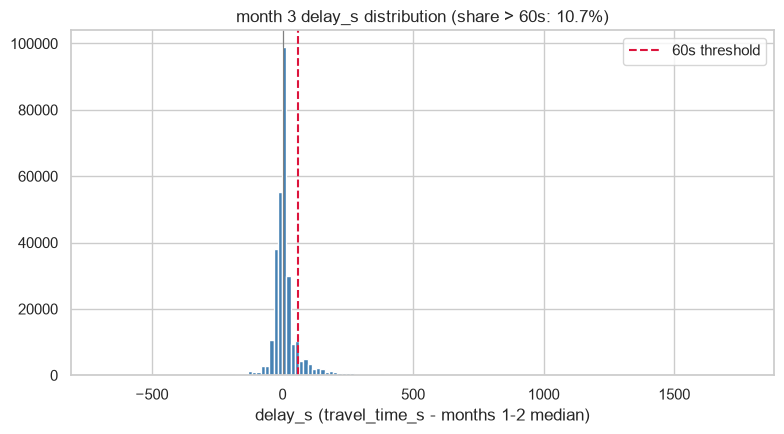

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(month3["delay_s"], bins=150, color="steelblue")
ax.axvline(60, color="crimson", linestyle="--", label="60s threshold")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_title(f"month 3 delay_s distribution (share > 60s: {share_over_60:.1%})")
ax.set_xlabel("delay_s (travel_time_s - months 1-2 median)")
ax.legend()
fig.tight_layout()
savefig(fig, "16_delay_vs_typical.png")
plt.show()
